# Reducing the unseen-hospital drop

Day 26 showed that a sepsis model loses accuracy at a hospital it has never seen, and that its alarm level stops
fitting. Here we test ways to reduce that drop, each on **the same test patients** as Day 26, for both hospital
systems (A and B):

| Fix | What the new hospital needs |
|---|---|
| **Re-tune the alarm level locally** (same model) | a little local data, no retraining |
| **Remove the "measuring routine" features** (hours since a vital was last measured) | nothing |
| **Fine-tune** with 5%, 10% or 20% of the new hospital's patients (3 repeats each) | a small local dataset |
| **Federated ensemble**: each hospital trains at home; only the *models* are shared | no patient data shared |
| **Federated averaging (FedAvg)**: one logistic regression trained together, sharing only weights | no patient data shared |
| *Pooled* (reference): both hospitals' data in one place | all patient data shared |
| *Home* (reference): trained entirely at the hospital itself | lots of local data |

Unless stated otherwise, every model's **alarm level is tuned on the hospital's own validation patients** to raise as
many alarms as NEWS2 ≥ 5 does there, so the "catches" column is a like-for-like comparison.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

warnings.filterwarnings("ignore", category=ConvergenceWarning)
DATA, RESULTS = Path("../data/physionet2019"), Path("../results")
df = pd.read_parquet(DATA / "risk_features.parquet")
FEATURES = pd.read_csv(DATA / "risk_feature_names.csv", header=None)[0].tolist()
ROUTINE = [f for f in FEATURES if f.endswith("_hours_since")]
WITHOUT_ROUTINE = [f for f in FEATURES if f not in ROUTINE]

# Same patient groups as Day 26: per hospital, training patients (minus 10% validation) and test patients.
groups = {}
for hospital in ("A", "B"):
    train = df[(df.hospital == hospital) & (df.split == "train")]
    patients = train.patient.unique()
    validation = set(np.random.default_rng(7).choice(patients, size=len(patients) // 10, replace=False))
    groups[hospital] = {
        "fit": train[~train.patient.isin(validation)],
        "validation": train[train.patient.isin(validation)],
        "test": df[(df.hospital == hospital) & (df.split == "test")],
    }
    print(hospital, {name: f"{part.patient.nunique():,} patients" for name, part in groups[hospital].items()})
OTHER = {"A": "B", "B": "A"}

A {'fit': '14,673 patients', 'validation': '1,630 patients', 'test': '4,033 patients'}


B {'fit': '14,399 patients', 'validation': '1,599 patients', 'test': '4,002 patients'}


In [2]:
def xgboost(features, fit, validation, base=None, rounds=1000):
    """XGBoost with Day 25's settings; `base` continues training an existing model (fine-tuning)."""
    weight = (fit.target == 0).sum() / max(1, (fit.target == 1).sum())
    model = xgb.XGBClassifier(
        n_estimators=rounds, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
        min_child_weight=20, scale_pos_weight=weight, eval_metric="aucpr", early_stopping_rounds=50,
        tree_method="hist", n_jobs=-1, random_state=0,
    )
    return model.fit(fit[features], fit.target, eval_set=[(validation[features], validation.target)],
                     xgb_model=None if base is None else base.get_booster(), verbose=False)


def alarm_level(scores, frame):
    """The score above which a model alarms as often as NEWS2 >= 5 does in this frame."""
    return float(np.quantile(scores, 1 - (frame.news2 >= 5).mean()))


def evaluate(scores, test, threshold):
    alarms = scores >= threshold
    return {"AUROC": roc_auc_score(test.target, scores), "AUPRC": average_precision_score(test.target, scores),
            "hours alarmed %": 100 * alarms.mean(), "catches %": 100 * alarms[test.target == 1].mean()}


models = {}
for hospital in ("A", "B"):
    g = groups[hospital]
    models[hospital] = xgboost(FEATURES, g["fit"], g["validation"])
    models[f"{hospital} without routine"] = xgboost(WITHOUT_ROUTINE, g["fit"], g["validation"])
pooled_fit = pd.concat([groups["A"]["fit"], groups["B"]["fit"]])
pooled_validation = pd.concat([groups["A"]["validation"], groups["B"]["validation"]])
models["pooled"] = xgboost(FEATURES, pooled_fit, pooled_validation)
print("Trained:", ", ".join(models))

Trained: A, A without routine, B, B without routine, pooled


## Fine-tuning with a little local data

The new hospital lends a small share of its training patients (5%, 10% or 20%). 70% of them are used to keep
training the other hospital's model (adding trees that fit local patterns), 30% to decide when to stop and to set
the local alarm level. Each share is repeated with **3 different random samples** of patients.

In [3]:
def fine_tune(target, share, seed):
    g = groups[target]
    patients = g["fit"].patient.unique()
    rng = np.random.default_rng(seed)
    local = rng.choice(patients, size=max(10, int(len(patients) * share)), replace=False)
    tune_on = set(local[: int(len(local) * 0.7)])
    local_rows = g["fit"][g["fit"].patient.isin(local)]
    tune, check = local_rows[local_rows.patient.isin(tune_on)], local_rows[~local_rows.patient.isin(tune_on)]
    model = xgboost(FEATURES, tune, check, base=models[OTHER[target]], rounds=300)
    return model, alarm_level(model.predict_proba(check[FEATURES])[:, 1], check)


fine_tuned = {(target, share, seed): fine_tune(target, share, seed)
              for target in ("A", "B") for share in (0.05, 0.10, 0.20) for seed in (1, 2, 3)}
print(len(fine_tuned), "fine-tuned models")

18 fine-tuned models


## Federated averaging (FedAvg)

Each hospital keeps its patients at home. Every round:
1. the server sends the current shared model (logistic regression weights) to both hospitals;
2. each hospital improves it on its own patients with a few careful (L-BFGS) steps;
3. each sends back only its updated **weights**; the server averages them (weighted by patient-hours).

Missing values are filled with, and features scaled by, the **overall** mean and spread, worked out from each
hospital's **counts, sums and sums of squares** only: summary numbers, never patient rows.
For comparison, the same logistic regression is also trained the ordinary way on the pooled data.

In [4]:
def summary_stats(frame):
    values = frame[FEATURES]
    return values.count(), values.sum(), (values ** 2).sum()


counts, sums, squares = (sum(parts) for parts in zip(*(summary_stats(groups[h]["fit"]) for h in ("A", "B"))))
mean = sums / counts
std = np.sqrt(squares / counts - mean ** 2).replace(0, 1)


def prepare(frame):
    return ((frame[FEATURES].fillna(mean) - mean) / std).values


site_data = {h: (prepare(groups[h]["fit"]), groups[h]["fit"].target.values) for h in ("A", "B")}


def local_steps(X_site, y_site, coef, intercept, steps=10):
    """A hospital improves the shared model on its own patients: a few L-BFGS steps, starting from the shared weights."""
    local = LogisticRegression(max_iter=steps, class_weight="balanced", warm_start=True)
    local.coef_, local.intercept_ = coef.copy(), intercept.copy()
    local.fit(X_site, y_site)
    return local.coef_, local.intercept_


coef, intercept = np.zeros((1, len(FEATURES))), np.zeros(1)
history = []
for round_ in range(20):
    updates = [local_steps(X_site, y_site, coef, intercept) for X_site, y_site in site_data.values()]
    share = np.array([len(y) for _, y in site_data.values()], dtype=float)
    share /= share.sum()
    coef = sum(s * c for s, (c, _) in zip(share, updates))
    intercept = sum(s * i for s, (_, i) in zip(share, updates))
    history.append(coef.copy())


def federated_lr(frame):
    return 1 / (1 + np.exp(-np.clip(prepare(frame) @ coef.T + intercept, -30, 30).ravel()))


X_pool = np.vstack([site_data[h][0] for h in ("A", "B")])
y_pool = np.concatenate([site_data[h][1] for h in ("A", "B")])
pooled_lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(X_pool, y_pool)
change = np.abs(history[-1] - history[-2]).max()
print(f"FedAvg: 20 rounds done; weights still changing by at most {change:.4f} per round")

FedAvg: 20 rounds done; weights still changing by at most 0.0012 per round


## The main results table

In [5]:
rows = []
for target in ("A", "B"):
    g, other = groups[target], OTHER[target]
    test, validation = g["test"], g["validation"]

    def add(method, scores, threshold, data_shared):
        rows.append({"hospital": target, "method": method, "patient data shared": data_shared,
                     **evaluate(scores, test, threshold)})

    def locally_tuned(method, score_fn, data_shared):
        add(method, score_fn(test), alarm_level(score_fn(validation), validation), data_shared)

    news2 = test.news2.values.astype(float)
    add("NEWS2 ≥ 5", news2, 5, "none")

    unseen = models[other]
    source_level = alarm_level(unseen.predict_proba(groups[other]["validation"][FEATURES])[:, 1], groups[other]["validation"])
    add("Unseen model, alarm level from the other hospital", unseen.predict_proba(test[FEATURES])[:, 1], source_level, "none")
    locally_tuned("Unseen model + alarm level re-tuned locally", lambda f: unseen.predict_proba(f[FEATURES])[:, 1], "none")

    no_routine = models[f"{other} without routine"]
    locally_tuned("Unseen model without routine features (+ re-tuned)", lambda f: no_routine.predict_proba(f[WITHOUT_ROUTINE])[:, 1], "none")

    for share in (0.05, 0.10, 0.20):
        repeats = [evaluate(model.predict_proba(test[FEATURES])[:, 1], test, level)
                   for (t, s, _), (model, level) in fine_tuned.items() if t == target and s == share]
        averaged = {key: np.mean([r[key] for r in repeats]) for key in repeats[0]}
        spread = np.std([r["AUROC"] for r in repeats])
        rows.append({"hospital": target, "method": f"Fine-tuned with {int(share * 100)}% local patients",
                     "patient data shared": "none", **averaged, "AUROC ± (3 repeats)": spread})

    ensemble = lambda f: (models["A"].predict_proba(f[FEATURES])[:, 1] + models["B"].predict_proba(f[FEATURES])[:, 1]) / 2  # noqa: E731
    locally_tuned("Federated ensemble (A + B models averaged)", ensemble, "none")
    locally_tuned("Federated averaging (FedAvg logistic regression)", federated_lr, "none")
    locally_tuned("Pooled logistic regression (reference)", lambda f: pooled_lr.predict_proba(prepare(f))[:, 1], "all")
    locally_tuned("Pooled XGBoost (reference)", lambda f: models["pooled"].predict_proba(f[FEATURES])[:, 1], "all")
    locally_tuned("Home model (reference)", lambda f: models[target].predict_proba(f[FEATURES])[:, 1], "own only")

results = pd.DataFrame(rows)
results.to_csv(RESULTS / "risk_main_results.csv", index=False)
for target in ("A", "B"):
    print(f"\nTested on hospital {target}:")
    view = results[results.hospital == target].set_index("method")[["AUROC", "AUPRC", "hours alarmed %", "catches %", "patient data shared"]]
    print(view.round({"AUROC": 3, "AUPRC": 3, "hours alarmed %": 1, "catches %": 1}).to_string())


Tested on hospital A:
                                                    AUROC  AUPRC  hours alarmed %  catches % patient data shared
method                                                                                                          
NEWS2 ≥ 5                                           0.627  0.021             29.7       47.3                none
Unseen model, alarm level from the other hospital   0.739  0.056             17.6       49.6                none
Unseen model + alarm level re-tuned locally         0.739  0.056             30.1       64.6                none
Unseen model without routine features (+ re-tuned)  0.725  0.053             30.5       61.7                none
Fine-tuned with 5% local patients                   0.733  0.053             31.1       63.3                none
Fine-tuned with 10% local patients                  0.739  0.053             30.5       64.6                none
Fine-tuned with 20% local patients                  0.753  0.057         

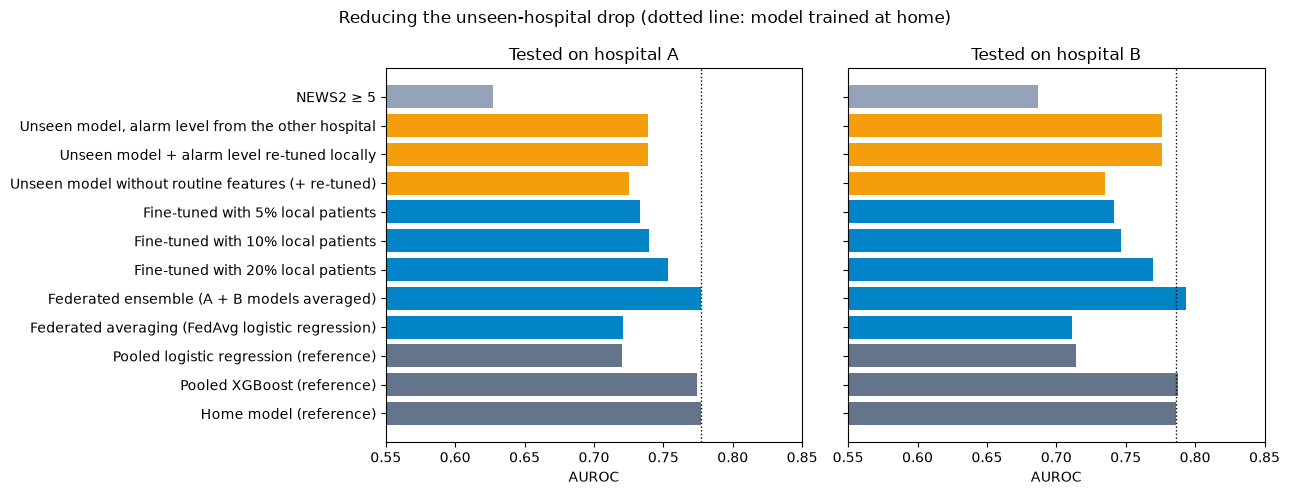

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, target in zip(axes, ("A", "B")):
    view = results[results.hospital == target].set_index("method")["AUROC"]
    colors = ["#94a3b8" if "NEWS2" in m else "#f59e0b" if "Unseen" in m else "#0284c7" if ("Fine" in m or "Federated" in m)
              else "#64748b" for m in view.index]
    ax.barh(view.index[::-1], view.values[::-1], color=colors[::-1])
    ax.set_xlim(0.55, 0.85)
    ax.axvline(view["Home model (reference)"], color="black", ls=":", lw=1)
    ax.set_title(f"Tested on hospital {target}")
    ax.set_xlabel("AUROC")
    if target == "B":
        ax.set_yticklabels([])
fig.suptitle("Reducing the unseen-hospital drop (dotted line: model trained at home)")
plt.tight_layout()
plt.savefig(RESULTS / "risk_main_results.png", dpi=150)
plt.show()

## Notes for the report

* Compare every fix with two rows: **"Unseen model, alarm level from the other hospital"** (what you get by just
  installing someone else's model) and **"Home model"** (what you'd get with plenty of local data).
* **Re-tuning the alarm level** needs no retraining at all, only local validation data, and fixes the alarm load.
* **Fine-tuning** shows how much local data is enough; the ± column shows how much it depends on *which* patients.
* **Federated** methods need **no patient data to leave either hospital**; compare them with the pooled references,
  which do.